Features after encoding: 39
Train: (40000, 39) Test: (10000, 39)
Placed % in train: 30.3%


Logistic Regression    Acc 85.18% | F1 77.93% | AUC 0.9371


Decision Tree          Acc 81.25% | F1 74.24% | AUC 0.9135


Random Forest          Acc 88.14% | F1 81.13% | AUC 0.9518


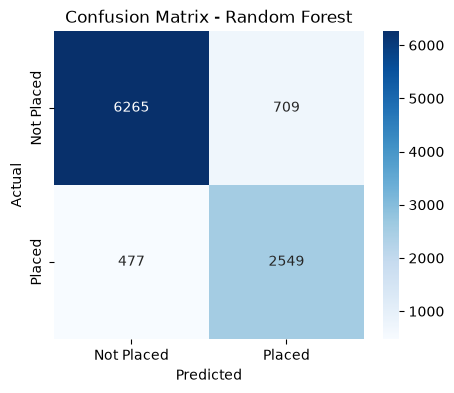

TP: 2549 | TN: 6265 | FP: 709 | FN: 477


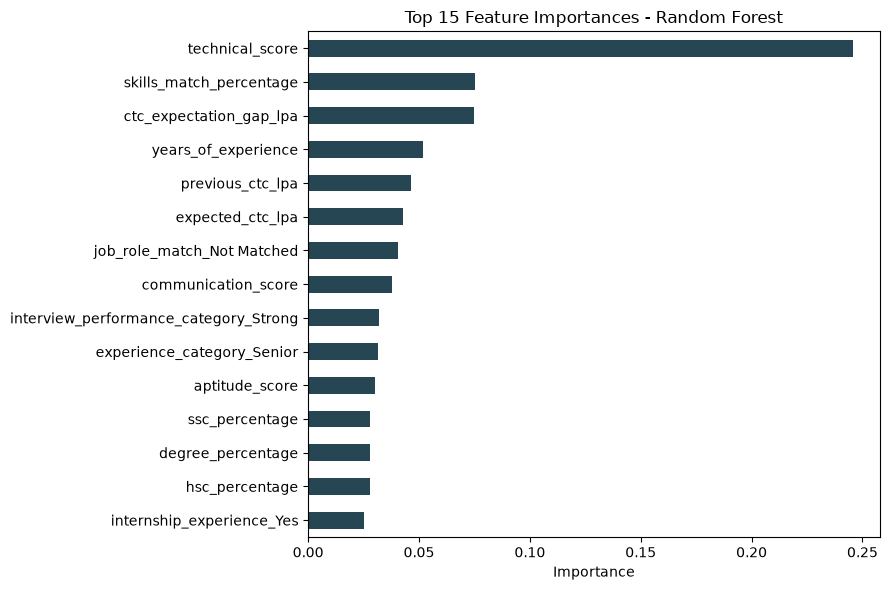

technical_score                          0.245623
skills_match_percentage                  0.075467
ctc_expectation_gap_lpa                  0.074990
years_of_experience                      0.051834
previous_ctc_lpa                         0.046218
expected_ctc_lpa                         0.042767
job_role_match_Not Matched               0.040296
communication_score                      0.037908
interview_performance_category_Strong    0.031960
experience_category_Senior               0.031487
dtype: float64
Model saved as model.pkl


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

%matplotlib inline

df = pd.read_csv("Final_Dataset.csv")

# target: Placed -> 1 (accepted), Not Placed -> 0 (rejected)
df["target"] = (df["status"] == "Placed").astype(int)

y = df["target"]
X = df.drop(columns=["status", "target"])

# keep the list of original numeric columns (needed for scaling and for the app)
num_cols = X.select_dtypes(include="number").columns.tolist()

# one-hot encode the categorical columns
X = pd.get_dummies(X, drop_first=True)
print("Features after encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Placed %% in train: %.1f%%" % (y_train.mean() * 100))

# scale only the original numeric columns
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train.head()

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=200,
                                           random_state=42, n_jobs=-1),
}

results = []
fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred), 4),
        "Recall": round(recall_score(y_test, pred), 4),
        "F1": round(f1_score(y_test, pred), 4),
        "ROC_AUC": round(roc_auc_score(y_test, prob), 4),
    })
    print(f"{name:22s} Acc {results[-1]['Accuracy']*100:.2f}% | "
          f"F1 {results[-1]['F1']*100:.2f}% | AUC {results[-1]['ROC_AUC']:.4f}")

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
results_df

# confusion matrix of the best model (Random Forest)
best = fitted["Random Forest"]
pred = best.predict(X_test)
cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Placed", "Placed"], yticklabels=["Not Placed", "Placed"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()
print("TP:", cm[1, 1], "| TN:", cm[0, 0], "| FP:", cm[0, 1], "| FN:", cm[1, 0])

# feature importance
importance = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
importance.head(15).sort_values().plot(kind="barh", color="#264653")
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/7_feature_importance.png", bbox_inches="tight")
plt.show()
print(importance.head(10))

# save the best model + everything the Streamlit app needs
joblib.dump({"model": best, "scaler": scaler,
             "columns": list(X.columns), "num_cols": num_cols}, "model.pkl")
print("Model saved as model.pkl")